# NaN Count Audit

Standalone missing-value audit built on the **`mainmain.ipynb` architecture**
(column selection → age ≥ 40 filter → `O_TC` cleaning → invalid-code replacement),
extended with two additional survey variables:

- **`BS3_1`** — current cigarette smoking status
- **`BD1_11`** — alcohol consumption frequency (past year)

The goal of this notebook is only the **NaN count** and its visualisation.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load dataset

In [4]:
df = pd.read_csv('../csv/KNHANES9.csv')
print(df.shape)

(6997, 798)


/var/folders/xt/mzqh8hz12q76z91q0t6kvzqm0000gn/T/ipykernel_37110/2029567252.py:1: DtypeWarning: Columns (11,12,13,14,24,25,27,28,29,30,31,32,33,34,35,36,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,63,64,65,66,67,69,70,71,72,73,74,75,76,78,79,80,81,82,83,84,85,86,87,88,89,90,91,93,94,95,96,97,98,99,100,101,102,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,134,135,136,137,138,139,140,141,142,144,145,146,147,148,149,150,151,152,153,155,156,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,249,250,251,252,253,254,255,256,257,258,259,260,261,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,283,284,285,286,287,288,289,291,292,294,295,296,297,298,300,301,302,303,304,305,306,307,308,309,310,311,312,313,314,315,316,317,318,319,320,321,322,323,324,325,326,327,328,329,330

## 2. Feature selection & age filter

Same as the main notebook: select the candidate columns — now including the two
added variables `BS3_1` and `BD1_11` — and restrict to respondents aged ≥ 40.

In [5]:
raw_columns = ['age', 'sex', 'ho_incm', 'edu', 'BD1', 'BM7',
               'HE_HbA1c', 'HE_BMI', 'HE_crea', 'O_TC']   # <-- two variables added to the architecture

age_threshold = 40
df_subset = df[raw_columns].copy()
df_subset = df_subset[df_subset['age'] >= age_threshold]
print(df_subset.shape)

(4680, 10)


## 3. Target cleaning (`O_TC`)

Coerce `O_TC`, null the `-1.80E+308` sentinel, and drop rows with a missing tooth
count so the audit runs on the same cohort the main notebook models.

In [6]:
df_subset['O_TC'] = pd.to_numeric(df_subset['O_TC'], errors='coerce')
df_subset['O_TC'] = df_subset['O_TC'].replace(-1.80e308, np.nan)
df_subset = df_subset.dropna(subset=['O_TC'])
print(f"Rows after O_TC clean: {len(df_subset)}")

Rows after O_TC clean: 4147


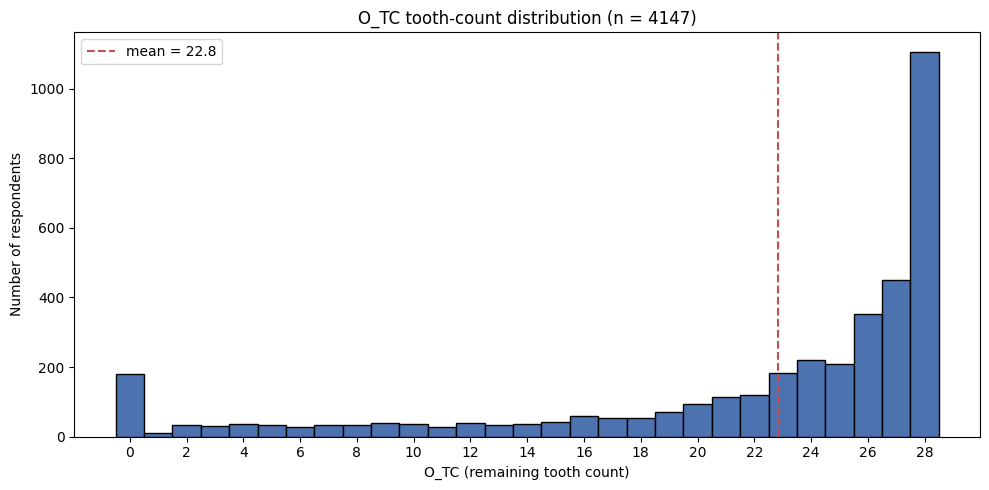

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_subset['O_TC'], bins=range(0, 30), color='#4C72B0',
        edgecolor='black', align='left')
ax.set_xlabel('O_TC (remaining tooth count)')
ax.set_ylabel('Number of respondents')
ax.set_title(f'O_TC tooth-count distribution (n = {len(df_subset)})')
ax.set_xticks(range(0, 29, 2))

mean_tc = df_subset['O_TC'].mean()
ax.axvline(mean_tc, color='#C44E52', linestyle='--', linewidth=1.5,
           label=f'mean = {mean_tc:.1f}')
ax.legend()

plt.tight_layout()
plt.show()

## 4. Invalid-code replacement

Survey reserved codes (8, 9, 88, 99, 888, 999) and lab sentinels become `NaN`.
`BS3_1` and `BD1_11` are survey N(1) variables, so they join `survey_cols`.

In [8]:
invalid_codes = [8, 9, 88, 99, 888, 999]
survey_cols = ['BD1', 'edu', 'ho_incm', 'BM7']  # 2 added
lab_cols    = ['HE_HbA1c', 'HE_BMI', 'HE_crea']

df_subset[survey_cols] = df_subset[survey_cols].replace(invalid_codes, np.nan)
df_subset[lab_cols] = df_subset[lab_cols].apply(pd.to_numeric, errors='coerce')
df_subset[lab_cols] = df_subset[lab_cols].where(df_subset[lab_cols].abs() < 1e10, np.nan)
df_subset.loc[df_subset['HE_crea'] <= 0, 'HE_crea'] = np.nan

## 5. NaN count per variable

In [9]:
audit_cols = survey_cols + lab_cols
total = len(df_subset)
na_counts = df_subset[audit_cols].isna().sum().sort_values(ascending=False)

print(f"Total rows: {total}\n")
for col, n in na_counts.items():
    print(f"{col:>10}: {n:4d}  ({n / total * 100:.1f}%)")

Total rows: 4147

  HE_HbA1c:  123  (3.0%)
   HE_crea:  123  (3.0%)
    HE_BMI:   79  (1.9%)
       BM7:   53  (1.3%)
       BD1:   52  (1.3%)
       edu:    0  (0.0%)
   ho_incm:    0  (0.0%)


## 6. NaN count bar plot

In [1]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(na_counts.index, na_counts.values, color='#C44E52', edgecolor='black')
ax.set_ylabel('NaN count')
ax.set_xlabel('Variable')
ax.set_title(f'Missing-value count per variable (n = {total})')
plt.xticks(rotation=45, ha='right')

# annotate each bar with count and percentage
for bar, n in zip(bars, na_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n,
            f'{n}\n({n / total * 100:.1f}%)', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined